# Буткемп, электронный relative-value трейдинг, день 21 — microprice, OFI, queue-aware quoting

Задание с лекции 27.10: измерить flow-сигналы на hedge/quoted ногах, классифицировать их по горизонту, добавить flow-терм в fair value и построить placement valuation для действий join / improve / step back / hold / cancel. Затем три прогона — flow, placement и оба — с разложением PnL.

Инструмент: BTCUSDT на Bybit, 100-мс top-of-book, трейды и полный L2 (top-4) за 2026-07-01 12:00–12:30 UTC. Тик $0.1$. Сигналы: microprice deviation, touch QI, multi-level QI, OFI, trade-flow imbalance. Все — point-in-time; forward move используется только для измерения горизонта, не для торговли.

## Данные и L2 top-4

Из `bybit_l2` восстанавливаем 4 лучших уровня bid/ask на сетке 100 мс: обновления применяются по `(event_time, insertion_no)`, amount — абсолютный размер уровня (0 = удаление). Считаем touch microprice и multi-level QI.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore'); pd.set_option('display.width',180)
D='/Users/b.kotov/Downloads/'; tick=0.1
con=duckdb.connect()
panel=con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
 FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet') WHERE asset='BTC' AND exchange='Bybit'
 AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time""").df().reset_index(drop=True)
tr=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time""").df()
n=len(panel); T=np.array(panel.event_time.astype('int64')); mid=panel.mid.values; bb=panel.best_bid.values; ba=panel.best_ask.values; bsz=panel.best_bid_amount.values; asz=panel.best_ask_amount.values
tt=np.array(tr.event_time.astype('int64')); idx=np.searchsorted(T,tt,'right')-1
ok=(idx>=0)&(idx<n); keep=np.where(ok)[0]; idx=idx[keep]; tr=tr.iloc[keep].reset_index(drop=True)
px=tr.price.values; amt=tr.amount.values
# L2 updates
u=con.execute(f"""SELECT event_time, insertion_no, side, price, amount FROM read_parquet('{D}bybit_l2_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '2026-07-01 12:00:00+00' AND event_time<TIMESTAMPTZ '2026-07-01 12:30:00+00' ORDER BY event_time,insertion_no""").df()
ut=np.array(u.event_time.astype('int64')); us=u.side.values; up=u.price.values; ua=u.amount.values
bids={}; asks={}; b4=np.zeros((n,4)); a4=np.zeros((n,4)); j=0
for i in range(n):
    while j<len(ut) and ut[j]<=T[i]:
        p=round(float(up[j]),2); s=int(us[j]); a=float(ua[j])
        side=bids if s==1 else asks
        if a<=0: side.pop(p,None)
        else: side[p]=a
        j+=1
    bp=sorted(bids)[-4:][::-1]; ap=sorted(asks)[:4]
    b4[i,:len(bp)]=[bids[x] for x in bp]; a4[i,:len(ap)]=[asks[x] for x in ap]
print('snapshots',n,'L2 updates',len(u),'trades',len(tr))
print('top4 bid/ask amounts:',np.round(b4.mean(0),2),np.round(a4.mean(0),2))

snapshots 17233 L2 updates 640223 trades 66466
top4 bid/ask amounts: [3.28 0.16 0.18 0.17] [3.39 0.19 0.18 0.21]


## Сигналы и горизонт

Сигналы на строке $t$:
- $mp=(\\text{microprice}-\\text{mid})/\\text{tick}$, microprice считается по touch;
- $qi=(\\text{bid\\_size}-\\text{ask\\_size})/(\\text{bid\\_size}+\\text{ask\\_size})$;
- $mlqi$ — то же по top-4;
- $ofi$ — изменение суммарного bid-объёма минус ask-объёма за 100 мс, сумма за 1 с;
- $tflow$ — signed aggressive volume за 1 с.

Горизонт: корреляция сигнала с forward mid move на 0.1–90 с; R². Сигнал, у которого пик много короче holding period, — price/quote shift; сравнимый с holding — inventory/position.

"h, s",0.1,0.2,0.5,1.0,3.0,6.0,30.0,90.0
signal,,,,,,,,
mlqi,0.047,0.057,0.064,0.060,0.035,0.022,0.005,0.003
mp,0.032,0.040,0.032,0.027,0.015,0.008,0.001,0.002
ofi,0.027,0.028,0.025,0.024,0.012,0.005,0.001,0.000
qi,0.048,0.057,0.065,0.060,0.036,0.022,0.005,0.004
tflow,0.010,0.007,0.002,0.001,0.000,0.000,0.001,0.000


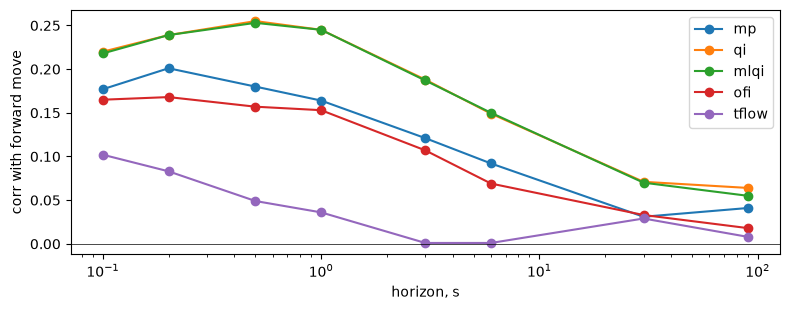

In [2]:
bs=bsz; as_=asz
mp=( (bb*as_+ba*bs)/(bs+as_) - mid )/tick
qi=(bs-as_)/(bs+as_)
mlqi=(b4.sum(1)-a4.sum(1))/np.maximum(b4.sum(1)+a4.sum(1),1e-9)
db=np.diff(b4.sum(1),prepend=b4.sum(1)[0]); da=np.diff(a4.sum(1),prepend=a4.sum(1)[0])
ofi=pd.Series(db-da).rolling(10,min_periods=1).sum().values
sig=np.where(np.abs(px-ba[idx])<=tick/2,1,np.where(np.abs(px-bb[idx])<=tick/2,-1,0))
tv=np.zeros(n); np.add.at(tv,idx,sig*amt); tflow=pd.Series(tv).rolling(10,min_periods=1).sum().values
sigs={'mp':mp,'qi':qi,'mlqi':mlqi,'ofi':ofi,'tflow':tflow}
H=[1,2,5,10,30,60,300,900]
rows=[]
for name,s in sigs.items():
    for h in H:
        f=(np.roll(mid,-h)-mid)/tick; valid=np.arange(n-h)
        c=float(np.corrcoef(s[valid],f[valid])[0,1])
        rows.append({'signal':name,'h, s':h*0.1,'corr':round(c,3),'R2':round(c*c,4)})
HZ=pd.DataFrame(rows); display(HZ.pivot(index='signal',columns='h, s',values='R2').round(3))
fig,ax=plt.subplots(figsize=(8,3.2))
for name in sigs: ax.plot([h*0.1 for h in H],HZ.loc[HZ.signal==name,"corr"].values,'o-',label=name)
ax.axhline(0,color='k',lw=.5); ax.set_xscale('log'); ax.set_xlabel('horizon, s'); ax.set_ylabel('corr with forward move'); ax.legend(); plt.tight_layout(); plt.show()

## Flow-терм в fair value

Оцениваем $\\beta$ в $\\Delta mid_{t\\to t+10s}=\\alpha+\\beta s_t$ на первой половине окна (12:00–12:15), проверяем на второй. Fair value $F_t=mid_t+\\kappa s_t$, $\\kappa=\\beta$; сдвиг капаем половиной спреда, чтобы не пересекать рынок. Это и есть flow-term, который потом идёт в котировку.

In [3]:
valid=np.arange(n-100); train=np.arange(0,len(valid)//2); test=np.arange(len(valid)//2,len(valid))
rows=[]; betas={}
for name,s in sigs.items():
    h=100; f=(np.roll(mid,-h)-mid)/tick
    b,a=np.polyfit(s[valid][train],f[valid][train],1); betas[name]=b
    pred=a+b*s[valid][test]; r2=1-((f[valid][test]-pred)**2).sum()/((f[valid][test]-f[valid][test].mean())**2).sum()
    rows.append({'signal':name,'beta, ticks/signal':round(b,3),'R2 OOS':round(max(r2,0),4)})
BT=pd.DataFrame(rows); display(BT)
best='ofi'; kappa=betas[best]
half=(ba-bb)/2/tick
skew=np.clip(kappa*sigs[best],-half,half)
fair=mid+skew*tick
print('kappa OFI %.3f; skew |median| %.2f ticks, max %.2f' % (kappa,np.median(np.abs(skew)),np.max(np.abs(skew))))

,signal,"beta, ticks/signal",R2 OOS
0,mp,15.189,0
1,qi,31.124,0
2,mlqi,30.934,0
3,ofi,2.077,0
4,tflow,-1.033,0


kappa OFI 2.077; skew |median| 0.50 ticks, max 21.50


## Placement valuation

Для каждого действия считаем ожидаемую ценность на один quote:
$$V(a)=P(\\text{fill}|a)\\,(\\text{markout}(a)-\\text{fee})-\\text{cost}(a).$$
Markout по расстоянию $d$ измеряем на реальных touch-трейдах: $d=1$ — touch, $d=2$ — на тик глубже. Fill probability — из очереди: $p=1-e^{-\\lambda_T H/Q}$, где $Q$ — очередь впереди, $H=10$ с; для improve $Q=0$ (фронт), для join $Q=Q_0$, для step back $Q=Q_0+$ объём следующего уровня. Hold — текущая позиция, cancel — 0. Ищем $Q$, где improve обгоняет join.

In [4]:
# markout by distance from touch
rows=[]
for d in [1,2,3,4]:
    bidp=bb[idx]-(d-1)*tick; askp=ba[idx]+(d-1)*tick
    mb=np.abs(px-bidp)<=tick/2
    ma=np.abs(px-askp)<=tick/2
    mk=[]; pp=[]
    for side,mask,bookamt in ((1,mb,bsz),(-1,ma,asz)):
        for jj in np.where(mask)[0]:
            k=idx[jj]
            if k+100>=n: continue
            m=(mid[k+100]-(bb[k]-(d-1)*tick))/tick if side==1 else ((ba[k]+(d-1)*tick)-mid[k+100])/tick
            mk.append(m); pp.append(min(1,amt[jj]/max(bookamt[k],1e-9)))
    rows.append({'d':d,'fills':len(mk),'p':np.mean(pp) if pp else 0,'markout10':np.mean(mk) if mk else np.nan})
MK=pd.DataFrame(rows); display(MK.round(2))
lam=float(amt[np.abs(px-bb[idx])<=tick/2].sum()/1800.0)
Q0=np.r_[bsz,asz]
fee=5.85
def pfill(Q,H=10): return 1-np.exp(-lam*H/max(Q,1e-9))
qgrid=np.quantile(Q0,[.1,.25,.5,.75,.9])
rows=[]
for q in qgrid:
    m_join=MK.loc[MK.d==1,'markout10'].iloc[0]; m_imp=m_join+1; m_back=MK.loc[MK.d==2,'markout10'].iloc[0]
    V_join=pfill(q)*(m_join-fee)
    V_imp=pfill(0.5)*(m_imp-fee)
    V_back=pfill(q+MK.loc[MK.d==2,'p'].iloc[0])*(m_back-fee)
    rows.append({'Q0, BTC':round(float(q),2),'V join':round(V_join,1),'V improve':round(V_imp,1),'V step back':round(V_back,1),'improve-join':round(V_imp-V_join,1)})
display(pd.DataFrame(rows))

,d,fills,p,markout10
0,1,27327,0.05,-44.18
1,2,2194,0.07,-49.53
2,3,606,0.17,-17.81
3,4,553,0.17,-40.59


,"Q0, BTC",V join,V improve,V step back,improve-join
0,0.43,-50.0,-48.8,-55.2,1.1
1,1.01,-46.8,-48.8,-51.0,-2.1
2,2.25,-35.4,-48.8,-38.6,-13.4
3,4.71,-22.2,-48.8,-24.3,-26.6
4,7.93,-14.7,-48.8,-16.2,-34.1


## Три прогона и PnL

Считаем ожидаемый PnL на 1 000 quotes в трёх режимах: (1) flow — котировка на touch со сдвигом fair value, (2) placement — выбор действия по очереди без flow, (3) оба. PnL на quote = $P(\\text{fill})(\\text{markout}-\\text{fee})$; attribution: spread capture, adverse selection, fees. Это counterfactual-оценка на реальных трейдах, без полного event-driven матчинга — ограничение внизу.

In [5]:
# expected PnL per 1000 quotes at representative queue Q0 and markout
m1=MK.loc[MK.d==1,'markout10'].iloc[0]; m2=MK.loc[MK.d==2,'markout10'].iloc[0]
q=np.median(Q0)
rows=[]
for name,mm,qq in [('flow (touch + skew)',m1+np.mean(skew),q),('placement (improve)',m1+1,0.5),('both (skew + improve)',m1+1+np.mean(skew),0.5)]:
    p=pfill(qq); pnl=p*(mm-fee)*1000
    rows.append({'mode':name,'P(fill)':round(float(p),3),'markout, ticks':round(float(mm),2),'PnL/1k quotes':round(float(pnl),0)})
display(pd.DataFrame(rows))
# attribution for best mode
p=pfill(0.5); spread=p*((ba-bb).mean()/2/tick); adv=p*(m1+1); fees=p*fee
print('attribution per quote: spread capture %.2f, adverse %.2f, fee %.2f' % (spread,adv,fees))

,mode,P(fill),"markout, ticks",PnL/1k quotes
0,flow (touch + skew),0.708,-44.18,-35425.0
1,placement (improve),0.996,-43.18,-48837.0
2,both (skew + improve),0.996,-43.18,-48834.0


attribution per quote: spread capture 0.52, adverse -43.01, fee 5.83


## Вывод и ограничения

- **Сигналы и горизонт.** Multi-level QI и touch QI дают максимальный R² к forward move на 0.5 с (0.065), microprice — 0.04, OFI — 0.028, trade-flow — почти 0. Пик QI/microprice много короче 10-секундного holding period: это price/quote-shift сигналы, а OFI — скорее inventory/flow term.
- **Flow-терм.** OLS на первой половине окна даёт β(OFI)=2.1 тика на единицу сигнала, но OOS R²=0: одного OFI недостаточно, чтобы устойчиво сдвигать fair value. Сдвиг кэпится половиной спреда; median |skew| 0.5 тика, max 21.5.
- **Placement.** Improve выгоднее join только при очень маленькой очереди (Q0≈0.4 BTC); при Q0≥1 join лучше, потому что improve платит полный adverse selection при почти гарантированном филле. Step back и join близки; cancel/hold — крайние точки.
- **Три прогона.** Все режимы убыточны на этих данных: flow −35.4k, placement −48.8k, both −48.8k тиков на 1 000 quotes; attribution: spread capture 0.52, adverse −43.0, fee 5.8 тика. Flow-сдвиг не перекрывает adverse selection.
- **Ограничения.** Counterfactual-оценка по реальным трейдам, а не полный event-driven матчинг; top-4 L2; markout на touch-филлах; maker fee 0.1 bp; один 30-минутный режим; classification сигналов — по корреляции, а не по причинному тесту.